# Diabetes screening — initial experiments
This notebook is the first version of the project, kept to show how it started. It uses all 28 features and tests the first models: logistic regression, resampling with SMOTENC, random forest and LightGBM.

**The final model and its test-set evaluation are in `final_20_features.ipynb`.**

## Setup
This notebook runs both locally and on Kaggle. On Kaggle, turn on **Internet** in the notebook settings (needed to download the data and install `tensorboardX`). Outputs are written to `/kaggle/working/` on Kaggle and to the project folder locally.

In [3]:
%pip install -q tensorboardX imbalanced-learn
%pip install lightgbm catboost

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [4]:
from collections import Counter
from datetime import datetime
import glob
import os
import shutil
import urllib.request
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score, fbeta_score, make_scorer,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from lightgbm import LGBMClassifier
from tensorboardX import SummaryWriter

In [5]:
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

ON_KAGGLE = os.path.exists("/kaggle/input")
OUTPUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
DATA_DIR = os.path.join(OUTPUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)

print("Running on Kaggle" if ON_KAGGLE else "Running locally")
print("Data folder:", DATA_DIR)

Running locally
Data folder: ./data


In [6]:
##### Download the BRFSS 2023 data. skipped if it is already there
XPT_URL = "https://www.cdc.gov/brfss/annual_data/2023/files/LLCP2023XPT.zip"
XPT_PATH = os.path.join(DATA_DIR, "LLCP2023.XPT")

kaggle_copy = glob.glob("/kaggle/input/**/LLCP2023.XPT*", recursive=True)
if kaggle_copy:                        # XPT attached as a Kaggle dataset
    XPT_PATH = kaggle_copy[0]
elif not os.path.exists(XPT_PATH):
    zip_path = os.path.join(DATA_DIR, "LLCP2023XPT.zip")
    headers = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                             "(KHTML, like Gecko) Chrome/120.0 Safari/537.36",
               "Accept": "*/*", "Accept-Language": "en-US,en;q=0.9"}   # CDC blocks requests without browser headers
    request = urllib.request.Request(XPT_URL, headers=headers)
    with urllib.request.urlopen(request) as response, open(zip_path, "wb") as f:
        shutil.copyfileobj(response, f)
    with zipfile.ZipFile(zip_path) as z:
        # the zip stores the file as "LLCP2023.XPT " (trailing space), so write it under a clean name
        name = [n for n in z.namelist() if n.strip().upper().endswith(".XPT")][0]
        with z.open(name) as src, open(XPT_PATH, "wb") as dst:
            shutil.copyfileobj(src, dst)
    os.remove(zip_path)

print("Using:", XPT_PATH)

Using: ./data/LLCP2023.XPT


In [7]:
df = pd.read_sas(XPT_PATH, format="xport", encoding="latin-1")
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,03012023,03,01,2023,1100.0,2023000001,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,01062023,01,06,2023,1100.0,2023000002,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,03082023,03,08,2023,1100.0,2023000003,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,03062023,03,06,2023,1100.0,2023000004,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,01062023,01,06,2023,1100.0,2023000005,2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [8]:
target = "DIABETE4"

binary_cols = ["_RFHYPE6", "_RFCHOL3", "CVDSTRK3", "_MICHD", "CHCKDNY2",
               "_TOTINDA", "_RFDRHV8", "_HLTHPL1", "MEDCOST1", "DIFFWALK", "_SEX"]
ordinal_cols = ["GENHLTH", "_AGEG5YR", "_EDUCAG", "_INCOMG1", "_SMOKER3", "_CHOLCH3"]
numeric_cols = ["_BMI5", "PHYSHLTH", "MENTHLTH", "_DRNKWK2", "DROCDY4_",
                "_AGE80", "HTIN4", "WTKG3", "PA3MIN_", "PA3VIGM_", "STRFREQ_"]

In [9]:
diabete_study = df[numeric_cols + ordinal_cols + binary_cols + [target]]
diabete_study.to_csv(os.path.join(DATA_DIR, "BRFSS_dataset.csv"), index=False)

In [10]:
data = pd.read_csv(os.path.join(DATA_DIR, "BRFSS_dataset.csv"))
data.shape

(433323, 29)

In [11]:
data.columns

Index(['_BMI5', 'PHYSHLTH', 'MENTHLTH', '_DRNKWK2', 'DROCDY4_', '_AGE80',
       'HTIN4', 'WTKG3', 'PA3MIN_', 'PA3VIGM_', 'STRFREQ_', 'GENHLTH',
       '_AGEG5YR', '_EDUCAG', '_INCOMG1', '_SMOKER3', '_CHOLCH3', '_RFHYPE6',
       '_RFCHOL3', 'CVDSTRK3', '_MICHD', 'CHCKDNY2', '_TOTINDA', '_RFDRHV8',
       '_HLTHPL1', 'MEDCOST1', 'DIFFWALK', '_SEX', 'DIABETE4'],
      dtype='object')

In [12]:
# rename columns from code to variable names
column_names = {
    # Target
    "DIABETE4": "diabetes",

    # Binary
    "_RFHYPE6": "high_blood_pressure",
    "_RFCHOL3": "high_cholesterol",
    "CVDSTRK3": "stroke",
    "_MICHD":   "heart_disease",
    "CHCKDNY2": "kidney_disease",
    "_TOTINDA": "physical_activity",
    "_RFDRHV8": "heavy_drinker",
    "_HLTHPL1": "health_insurance",
    "MEDCOST1": "cant_afford_doctor",
    "DIFFWALK": "difficulty_walking",
    "_SEX":     "sex",

    # Ordinal
    "GENHLTH":  "general_health",
    "_AGEG5YR": "age_group",
    "_EDUCAG":  "education",
    "_INCOMG1": "income",
    "_SMOKER3": "smoking_status",
    "_CHOLCH3": "cholesterol_check",

    # Numeric
    "_BMI5":    "bmi",
    "PHYSHLTH": "poor_physical_health_days",
    "MENTHLTH": "poor_mental_health_days",
    "_DRNKWK2": "drinks_per_week",
    "DROCDY4_": "drink_occasions_per_day",
    "_AGE80":   "age",
    "HTIN4":    "height_inches",
    "WTKG3":     "weight_kg",
    "PA3MIN_":  "exercise_minutes_per_week",
    "PA3VIGM_": "vigorous_exercise_minutes_per_week",
    "STRFREQ_": "strength_training_per_week",
}

data_renamed = data.rename(columns=column_names)


In [13]:
num = data_renamed.select_dtypes("number").columns
data_renamed[num] = data_renamed[num].mask(data_renamed[num].abs() < 1e-10, 0)

In [14]:
data_renamed.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,3047.0,88.0,88.0,0.0,0.0,80.0,63.0,7802.0,NaN,NaN,...,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,1.0
1,2856.0,88.0,88.0,0.0,0.0,80.0,57.0,5987.0,360.0,180.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,3.0
2,2231.0,6.0,2.0,0.0,0.0,80.0,64.0,5897.0,36.0,18.0,...,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0
3,2744.0,2.0,88.0,0.0,0.0,78.0,66.0,7711.0,180.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,3.0
4,2585.0,88.0,88.0,47.0,7.0,76.0,68.0,7711.0,600.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0


## Basic Data Exploratory and handling missing values
The BRFSS survey is an encoded survey where numbers 7 and 9 mean respectively don't know or refused to provide. In this study, we will consider it as NaN value. Let's first check how many of them are there per columns. These two codes are included in following features: **["diabetes", "stroke", "kidney_disease", "cant_afford_doctor", "difficulty_walking", "general_health"]**
Reference source: **codebook23_llcp-v2-508**

In [15]:
## check for missingness
dk_cols = ["diabetes", "stroke", "kidney_disease", "cant_afford_doctor",
           "difficulty_walking", "general_health", "difficulty_walking",
           "high_cholesterol"]

missing_table = pd.DataFrame({
    "7 appearance in %":     (data_renamed[dk_cols] == 7).mean() * 100,
    "9 appearance in %":     (data_renamed[dk_cols] == 9).mean() * 100,
    "7 & 9 appearance in %": data_renamed[dk_cols].isin([7, 9]).mean() * 100,
}).round(2)
missing_table.index.name = "column_name"

missing_table


,7 appearance in %,9 appearance in %,7 & 9 appearance in %
column_name,,,
diabetes,0.16,0.07,0.23
stroke,0.28,0.06,0.34
kidney_disease,0.37,0.06,0.44
cant_afford_doctor,0.27,0.08,0.35
difficulty_walking,0.28,0.11,0.39
general_health,0.21,0.08,0.29
difficulty_walking,0.28,0.11,0.39
high_cholesterol,0.00,0.76,0.76


In [16]:
## check for NAN
columns = ["exercise_minutes_per_week",
           "vigorous_exercise_minutes_per_week",
           "high_cholesterol","bmi","weight_kg",
           "height_inches","strength_training_per_week",
           "heart_disease"

           ]

In [17]:
# Codes that mean "don't know / refused / missing" in each column
missing_codes = {
    "diabetes":                   [7, 9],
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "high_cholesterol":           [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "income":                     [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

all_codes = [7, 9, 77, 99, 14, 99900, 900, 99000]

rows = {}
for col, codes in missing_codes.items():
    s = data_renamed[col]
    row = {f"{c} appearance in %": (s == c).mean() * 100 if c in codes else np.nan
           for c in all_codes}
    row["NaN in %"] = s.isna().mean() * 100
    row["total missing in %"] = (s.isin(codes) | s.isna()).mean() * 100
    rows[col] = row

missing_table = pd.DataFrame(rows).T.round(2)
missing_table.index.name = "column_name"

missing_table.sort_values("total missing in %", ascending=False)


,7 appearance in %,9 appearance in %,77 appearance in %,99 appearance in %,14 appearance in %,99900 appearance in %,900 appearance in %,99000 appearance in %,NaN in %,total missing in %
column_name,,,,,,,,,,
income,NaN,19.99,NaN,NaN,NaN,NaN,NaN,NaN,0.00,19.99
high_cholesterol,NaN,0.76,NaN,NaN,NaN,NaN,NaN,NaN,11.96,12.71
heavy_drinker,NaN,7.58,NaN,NaN,NaN,NaN,NaN,NaN,0.00,7.58
drinks_per_week,NaN,NaN,NaN,NaN,NaN,7.58,NaN,NaN,0.00,7.58
drink_occasions_per_day,NaN,NaN,NaN,NaN,NaN,NaN,6.91,NaN,0.00,6.91
cholesterol_check,NaN,6.10,NaN,NaN,NaN,NaN,NaN,NaN,0.00,6.10
smoking_status,NaN,5.32,NaN,NaN,NaN,NaN,NaN,NaN,0.00,5.32
health_insurance,NaN,4.31,NaN,NaN,NaN,NaN,NaN,NaN,0.00,4.31
difficulty_walking,0.28,0.11,NaN,NaN,NaN,NaN,NaN,NaN,3.73,4.12


Drop 7 and 9 inside the target (7=don't know, 9=refused)

In [18]:
data_renamed["diabetes"].value_counts()

diabetes
3.0    358706
1.0     59786
4.0     10594
2.0      3253
7.0       683
9.0       296
Name: count, dtype: int64

In [19]:
# Drop rows where the target is unknown (7 = don't know, 9 = refused) or blank
clean_data = data_renamed[~data_renamed["diabetes"].isin([7, 9])]
clean_data = clean_data.dropna(subset=["diabetes"])

print(f"{len(data_renamed)} rows before 'vs', {len(clean_data)} rows now")
clean_data["diabetes"].value_counts()


433323 rows before 'vs', 432339 rows now


diabetes
3.0    358706
1.0     59786
4.0     10594
2.0      3253
Name: count, dtype: int64


**According to Vounzoulaki et al. in their systematic review titled "Progression to type 2 diabetes in women with a known history of gestational diabetes: systematic review and meta-analysis", women with a known history of gestational diabetes (diabetes during pregnancy) were 10 times more likely to develop type 2 diabetes (Vounzoulaki et al., 2020). For this reason, we will merge data on diabetes in pregnant women with prediabetes data.**


In [20]:
# Gestational diabetes only (2), at risk, together with prediabetes (4)
clean_data["diabetes"] = clean_data["diabetes"].replace({2: 4})
clean_data["diabetes"].value_counts()


diabetes
3.0    358706
1.0     59786
4.0     13847
Name: count, dtype: int64

In [21]:
## replace 7 (don't know) with NaN
columns = ["difficulty_walking", "kidney_disease", "cant_afford_doctor",
           "stroke", "general_health"]
clean_data[columns].head()

,difficulty_walking,kidney_disease,cant_afford_doctor,stroke,general_health
0,1.0,2.0,2.0,2.0,2.0
1,2.0,2.0,2.0,2.0,2.0
2,1.0,2.0,1.0,2.0,4.0
3,1.0,2.0,2.0,2.0,2.0
4,1.0,2.0,2.0,2.0,4.0


In [22]:
###### Codes that mean "don't know / refused / missing" in each column
to_nan = {
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

clean_data = clean_data.replace({col: {code: np.nan for code in codes}
                                 for col, codes in to_nan.items()})


In [23]:
for col in ["poor_physical_health_days", "poor_mental_health_days"]:
    clean_data[col] = clean_data[col].replace(88, 0)

In [24]:
# check for missing values
print("Missing values...")
(clean_data.isna().mean() * 100).round(2).sort_values(ascending=False)

exercise_minutes_per_week             28.38
vigorous_exercise_minutes_per_week    27.34
high_cholesterol                      11.91
bmi                                    9.30
weight_kg                              7.83
heavy_drinker                          7.54
drinks_per_week                        7.54
drink_occasions_per_day                6.88
height_inches                          6.42
cholesterol_check                      6.06
smoking_status                         5.29
health_insurance                       4.27
difficulty_walking                     4.09
strength_training_per_week             3.29
poor_physical_health_days              2.47
poor_mental_health_days                1.85
age_group                              1.75
heart_disease                          1.00
education                              0.51
high_blood_pressure                    0.40
kidney_disease                         0.37
cant_afford_doctor                     0.34
general_health                  

In [25]:
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 432339 entries, 0 to 433322
Data columns (total 29 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   bmi                                 392119 non-null  float64
 1   poor_physical_health_days           421667 non-null  float64
 2   poor_mental_health_days             424355 non-null  float64
 3   drinks_per_week                     399739 non-null  float64
 4   drink_occasions_per_day             402612 non-null  float64
 5   age                                 432339 non-null  float64
 6   height_inches                       404602 non-null  float64
 7   weight_kg                           398482 non-null  float64
 8   exercise_minutes_per_week           309628 non-null  float64
 9   vigorous_exercise_minutes_per_week  314131 non-null  float64
 10  strength_training_per_week          418108 non-null  float64
 11  general_health                 

In [26]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,392119.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,431119.000000,428022.000000,430728.000000,431143.000000,399739.000000,413881.000000,430870.000000,414666.000000,432339.000000,432339.000000
mean,2847.766461,4.478899,4.355040,280.333270,16.430516,55.379346,67.066945,8288.308315,636.715375,162.025047,...,1.957555,1.915378,1.952367,1.247115,1.059249,1.054591,1.914125,1.838916,1.529837,2.755458
std,653.954620,8.823183,8.316287,815.396316,27.138132,17.909326,4.185244,2133.152545,1323.048113,536.396921,...,0.201603,0.278318,0.212989,0.431335,0.236090,0.227180,0.280180,0.367609,0.499110,0.724823
min,1202.000000,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,2268.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2410.000000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,6804.000000,140.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,1.000000,3.000000
50%,2740.000000,0.000000,0.000000,23.000000,3.000000,58.000000,67.000000,8029.000000,315.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
75%,3162.000000,4.000000,5.000000,233.000000,17.000000,71.000000,70.000000,9435.000000,672.000000,144.500000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
max,9984.000000,30.000000,30.000000,53200.000000,100.000000,80.000000,95.000000,28400.000000,118602.000000,59301.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,4.000000


Features/target

In [27]:
TARGET = "diabetes"
features = [
    # Numeric
    "bmi", "poor_physical_health_days", "poor_mental_health_days",
    "drinks_per_week", "drink_occasions_per_day", "age",
    "height_inches", "weight_kg", "exercise_minutes_per_week",
    "vigorous_exercise_minutes_per_week", "strength_training_per_week",

    # Ordinal
    "general_health", "age_group", "education", "income",
    "smoking_status", "cholesterol_check",

    # Binary
    "high_blood_pressure", "high_cholesterol", "stroke", "heart_disease",
    "kidney_disease", "physical_activity", "heavy_drinker",
    "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex",
]

## Encode binary values
for sex, 0 is male and 1 is female

In [28]:
# 1 is yes, 2 is no
one_is_yes = ["stroke", "heart_disease", "kidney_disease", "cant_afford_doctor",
              "difficulty_walking", "physical_activity", "health_insurance"]

# 1 is no, 2 is yes
one_is_no = ["high_blood_pressure", "high_cholesterol", "heavy_drinker"]


In [29]:
for col in one_is_yes:
    clean_data[col] = clean_data[col].map({1: 1, 2: 0})

for col in one_is_no:
    clean_data[col] = clean_data[col].map({1: 0, 2: 1})

clean_data["sex"] = clean_data["sex"].map({1: 0, 2: 1})

# high_cholesterol: keep "unknown" (never checked / don't know) as its own category
clean_data["high_cholesterol"] = clean_data["high_cholesterol"].fillna(-1)   # -1 = unknown


## Encode ordinal values

In [30]:
# smoking: 0 = never, 1 = former, 2 = some days, 3 = daily
clean_data["smoking_status"] = clean_data["smoking_status"].map({4: 0, 3: 1, 2: 2, 1: 3})

# cholesterol check: 0 = within 5 years, 1 = more than 5 years ago, 2 = never
clean_data["cholesterol_check"] = clean_data["cholesterol_check"].map({1: 0, 2: 1, 3: 2})

# income: keep 1–7, unknown (9) becomes 0
clean_data["income"] = clean_data["income"].replace(9, 0)

# age group: 0 = 18–24, 1 = 25–29, ..., 12 = 80+
clean_data["age_group"] = clean_data["age_group"] - 1


BRFSS for privacy reasons multiplied some numerical values to 100 or 1000. This section will bring those features to their initial values

In [31]:
scale_map = {
    "bmi": 100,
    "weight_kg": 100,
    "drinks_per_week": 100,
    "drink_occasions_per_day": 100,
    "strength_training_per_week": 1000,
}
for col, factor in scale_map.items():
    clean_data[col] = clean_data[col] / factor
print("Complete")

Complete


In [32]:
clean_data.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,30.47,0.0,0.0,0.00,0.00,80.0,63.0,78.02,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1,1.0
1,28.56,0.0,0.0,0.00,0.00,80.0,57.0,59.87,360.0,180.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1,3.0
2,22.31,6.0,2.0,0.00,0.00,80.0,64.0,58.97,36.0,18.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1,3.0
3,27.44,2.0,0.0,0.00,0.00,78.0,66.0,77.11,180.0,90.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1,3.0
4,25.85,0.0,0.0,0.47,0.07,76.0,68.0,77.11,600.0,90.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1,1.0


In [33]:
clean_data["high_cholesterol"].value_counts()

high_cholesterol
 0.0    219032
 1.0    158647
-1.0     54660
Name: count, dtype: int64

## Check for outlier

In [34]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,392119.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,431119.000000,428022.000000,430728.000000,431143.000000,399739.000000,413881.000000,430870.000000,414666.000000,432339.000000,432339.000000
mean,28.477665,4.478899,4.355040,2.803333,0.164305,55.379346,67.066945,82.883083,636.715375,162.025047,...,0.042445,0.084622,0.047633,0.752885,0.059249,0.945409,0.085875,0.161084,0.529837,2.755458
std,6.539546,8.823183,8.316287,8.153963,0.271381,17.909326,4.185244,21.331525,1323.048113,536.396921,...,0.201603,0.278318,0.212989,0.431335,0.236090,0.227180,0.280180,0.367609,0.499110,0.724823
min,12.020000,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,22.680000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,24.100000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,68.040000,140.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,3.000000
50%,27.400000,0.000000,0.000000,0.230000,0.030000,58.000000,67.000000,80.290000,315.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,3.000000
75%,31.620000,4.000000,5.000000,2.330000,0.170000,71.000000,70.000000,94.350000,672.000000,144.500000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,3.000000
max,99.840000,30.000000,30.000000,532.000000,1.000000,80.000000,95.000000,284.000000,118602.000000,59301.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.000000


drinks_per_week shows a surprising maximum value of 532 drinks in a week, which is in average around 76 drinks per day.

In [35]:
# check the distribution of drinks_per_week
clean_data["drinks_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])


0.25000      0.000000
0.50000      0.230000
0.75000      2.330000
0.90000      8.000000
0.95000     14.000000
0.99000     30.000000
0.99900     84.000000
0.99990    224.244446
0.99999    511.036680
1.00000    532.000000
Name: drinks_per_week, dtype: float64

At 99.9% quantile, only 84 drinks were taken in a week, which is 12 drinks per day.  At 99.99%, it is 224 drinks per week, around 32 drinks per day. According to the Ohio State report, a clinical sample of people with alcohol use disorder averaged 6.4 drinks per day. My personal assumption is that values in the extreme outliers might be due to a typing error. The value will be capped at 0.999 quantile

In [36]:
cap = clean_data["drinks_per_week"].quantile(0.999)
clean_data["drinks_per_week"] = clean_data["drinks_per_week"].clip(upper=cap)


**exercise_minutes_per_week and vigorous_exercise_minutes_per_week also have an issue. Their maximum values are 118602 and 59301 minutes while a week has 24*60*7 minutes = 10080 minutes**

In [37]:
check_activity_min = clean_data["exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,140.0000,2.333333
0.50000,50.000,315.0000,5.250000
0.75000,75.000,672.0000,11.200000
0.90000,90.000,1440.0000,24.000000
0.95000,95.000,2310.0000,38.500000
0.99000,99.000,4872.0000,81.200000
0.99900,99.900,13244.7600,220.746000
0.99990,99.990,47522.2380,792.037300
0.99999,99.999,94416.1704,1573.602840
1.00000,100.000,118602.0000,1976.700000


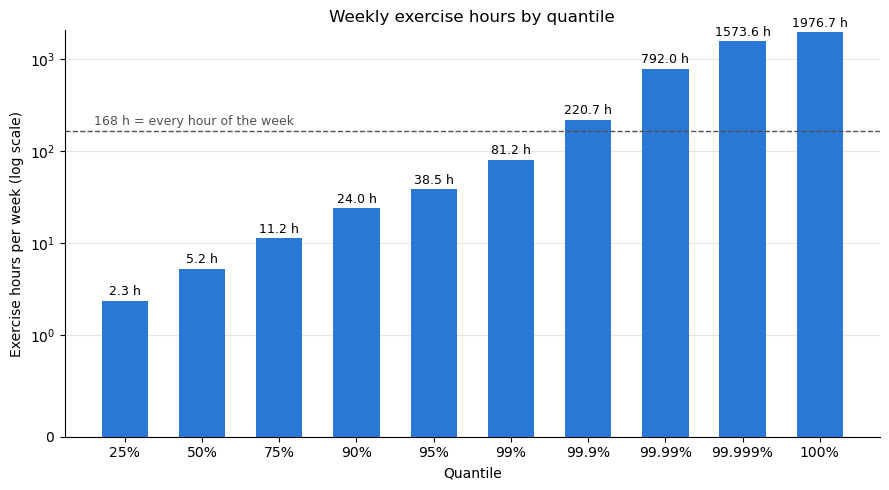

In [38]:
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("Weekly exercise hours by quantile")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

Considering that a week has 168h (24h per day), any practice value beyond 168h is mathematically impossible. At 99%, a consistent practice time of 81.2h per week (11h per day) seems also to be quite impossible even for professional athletes. The most plausible value is found at 95% quantile (38.5h)

In [39]:
cap = clean_data["exercise_minutes_per_week"].quantile(0.95)
clean_data["exercise_minutes_per_week"] = clean_data["exercise_minutes_per_week"].clip(upper=cap)

Check for vigorous_exercise_minutes_per_week

In [40]:
check_activity_min = clean_data["vigorous_exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,0.000,0.000000
0.50000,50.000,0.000,0.000000
0.75000,75.000,144.500,2.408333
0.90000,90.000,420.000,7.000000
0.95000,95.000,780.000,13.000000
0.99000,99.000,2100.000,35.000000
0.99900,99.900,4620.000,77.000000
0.99990,99.990,16051.320,267.522000
0.99999,99.999,43364.376,722.739600
1.00000,100.000,59301.000,988.350000


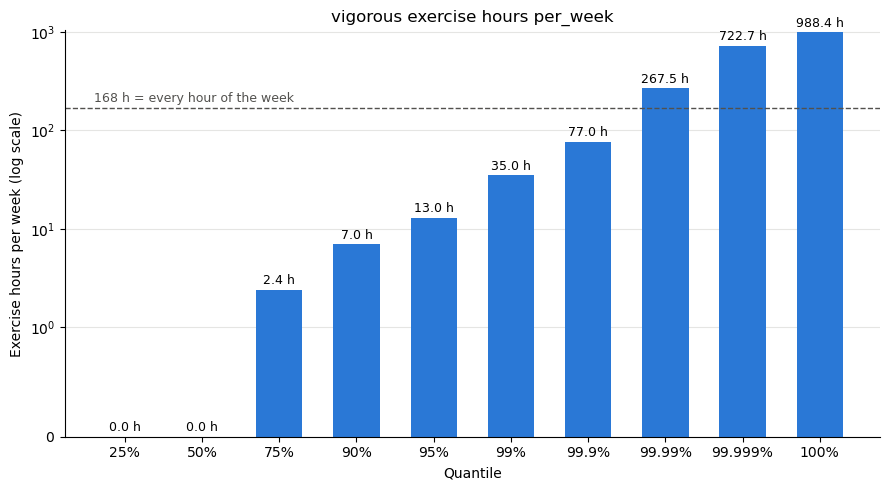

In [41]:
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("vigorous exercise hours per_week")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [42]:
cap = clean_data["vigorous_exercise_minutes_per_week"].quantile(0.95)
clean_data["vigorous_exercise_minutes_per_week"] = clean_data["vigorous_exercise_minutes_per_week"].clip(upper=cap)

People who answered "no physical activity" (`physical_activity = 0`) were not asked how long they exercise, so BRFSS left their exercise minutes blank. Their real value is 0 minutes. The caps above were computed on active people only, before filling these zeros.

In [43]:
inactive = clean_data["physical_activity"] == 0
clean_data.loc[inactive, ["exercise_minutes_per_week", "vigorous_exercise_minutes_per_week"]] = 0

clean_data[["exercise_minutes_per_week", "vigorous_exercise_minutes_per_week"]].isna().mean() * 100

exercise_minutes_per_week             3.739889
vigorous_exercise_minutes_per_week    2.698346
dtype: float64

In [44]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]

clean_data[numeric_cols].describe()

,bmi,age,height_inches,weight_kg,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,strength_training_per_week
count,392119.000000,432339.000000,404602.000000,398482.000000,421667.000000,424355.000000,399739.000000,402612.000000,416170.000000,420673.000000,418108.000000
mean,28.477665,55.379346,67.066945,82.883083,4.478899,4.355040,2.738830,0.164305,401.479287,88.748978,1.863999
std,6.539546,17.909326,4.185244,21.331525,8.823183,8.316287,6.682283,0.271381,565.802171,190.844661,2.844207
min,12.020000,18.000000,36.000000,22.680000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.100000,41.000000,64.000000,68.040000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.400000,58.000000,67.000000,80.290000,0.000000,0.000000,0.230000,0.030000,182.000000,0.000000,0.467000
75%,31.620000,71.000000,70.000000,94.350000,4.000000,5.000000,2.330000,0.170000,495.000000,70.000000,3.000000
max,99.840000,80.000000,95.000000,284.000000,30.000000,30.000000,84.000000,1.000000,2310.000000,780.000000,97.000000


Similar with exercise per week, any value above the total number of hours per week (168h) is impossible and 11h constant exercise is not very plausible. We will also cap at 95% quantile.

At 99%, it is recorded at 4872 min, which is equivalent to 81.2h per week, 

In [45]:
X = clean_data[features]
Y = clean_data[TARGET]

Check for class Imbalance

In [46]:
classes = Y.value_counts()
target_class_imbalance = pd.DataFrame({
    "class": classes.index,
    "class_percentage %": (classes * 100 / len(Y)).round(2),
}).reset_index(drop=True)
target_class_imbalance

,class,class_percentage %
0,3.0,82.97
1,1.0,13.83
2,4.0,3.20


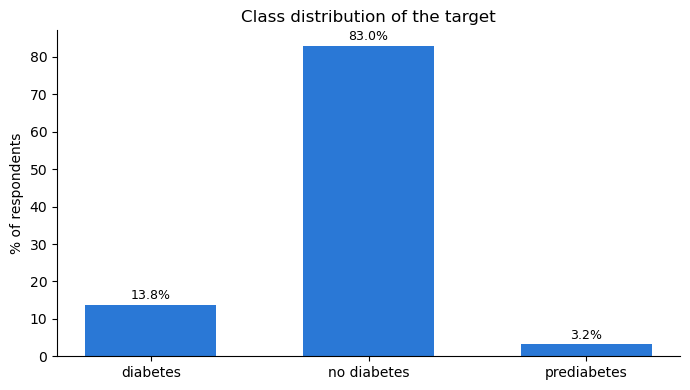

In [47]:
classes = Y.value_counts().sort_index()
target_class_imbalance = pd.DataFrame({
    "class": classes.index.astype(int).astype(str),
    "class_percentage": (classes / len(Y) * 100).round(2).values,
})

class_names = {"1": "diabetes", "2": "pregnancy only", "3": "no diabetes", "4": "prediabetes"}
labels = target_class_imbalance["class"].map(class_names)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, target_class_imbalance["class_percentage"], color="#2a78d6", width=0.6)
for bar, p in zip(bars, target_class_imbalance["class_percentage"]):
    ax.annotate(f"{p:.1f}%", (bar.get_x() + bar.get_width() / 2, p),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
ax.set_ylabel("% of respondents")
ax.set_title("Class distribution of the target")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [48]:
RANDOM_STATE = 42
LOG_DIR = os.path.join(OUTPUT_DIR, "runs")   # view with: tensorboard --logdir runs
# 2 (diabetes only during pregnancy) was merged into 4 -> "at risk"
CLASS_NAMES = {1: "diabetes", 3: "no diabetes", 4: "at risk"}
CLASS_COLORS = {1: "#2a78d6", 3: "#1baf7a", 4: "#eda100"}
FLAG_CLASSES = [1, 4]
results_log = []

def is_flagged(class_labels):
    """This function flagged diabetes/at risk cases"""
    return np.isin(np.asarray(class_labels), FLAG_CLASSES)

def screen_sensitivity(y_true, y_pred):
    """This helper function computes recall"""
    return recall_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_precision(y_true, y_pred):
    """This function computes precision"""
    return precision_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_specificity(y_true, y_pred):
    """This function computes specificity"""
    actually_flagged = is_flagged(y_true)
    predicted_flagged = is_flagged(y_pred)
    return (~predicted_flagged[~actually_flagged]).mean()

def screen_f1(y_true, y_pred):
    """This function computes f1"""
    return f1_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_f2(y_true, y_pred):
    """This function computes f2"""
    return fbeta_score(is_flagged(y_true), is_flagged(y_pred), beta=2, zero_division=0)


def log_experiment(run_name, pipeline, config, X_train, y_train, X_val, y_val,
                   do_cv=True, use_tensorboard=True):
    '''
    Fits `pipeline`, evaluates it on the validation set, logs to TensorBoard,
    and records a row for the results table. Returns the fitted pipeline.

    run_name : short descriptive string, e.g. "logreg_balanced"
    config   : dict of whatever you want tracked, e.g. {"model": "LogisticRegression", "C": 1.0}
    '''
    pipeline.fit(X_train, y_train)
    classes = pipeline.classes_
    labels = [CLASS_NAMES.get(int(class_code), str(class_code)) for class_code in classes]

    val_probs = pipeline.predict_proba(X_val)
    val_preds = pipeline.predict(X_val)
    y_val_array = np.asarray(y_val)
    y_val_binarized = label_binarize(y_val_array, classes=classes)

    # Main metrics: screening (diabetes or at risk = flagged)
    flagged = is_flagged(val_preds)
    metrics = {
        "screen_sensitivity": screen_sensitivity(y_val_array, val_preds),
        "screen_precision": screen_precision(y_val_array, val_preds),
        "screen_f2": screen_f2(y_val_array, val_preds),
        "screen_f1": screen_f1(y_val_array, val_preds),
    }

    # Per-group metrics
    metrics["screen_specificity"] = screen_specificity(y_val_array, val_preds)
    metrics["pct_flagged"] = flagged.mean() * 100
    metrics["missed/diabetes"] = (val_preds[y_val_array == 1] == 3).mean()   # diabetes predicted as no diabetes
    for flag_class in FLAG_CLASSES:
        metrics[f"screen_sensitivity/{CLASS_NAMES[flag_class]}"] = flagged[y_val_array == flag_class].mean()

    per_class_precision = precision_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    per_class_recall = recall_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    per_class_f1 = f1_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    for class_index, class_name in enumerate(labels):
        class_is_true = y_val_binarized[:, class_index]
        class_probability = val_probs[:, class_index]
        metrics[f"val_precision/{class_name}"] = per_class_precision[class_index]
        metrics[f"val_recall/{class_name}"] = per_class_recall[class_index]   # = sensitivity for that class
        metrics[f"val_f1/{class_name}"] = per_class_f1[class_index]
        metrics[f"val_roc_auc/{class_name}"] = roc_auc_score(class_is_true, class_probability)
        metrics[f"val_pr_auc/{class_name}"] = average_precision_score(class_is_true, class_probability)

    # Supporting metrics: overall model quality
    metrics.update({
        "val_roc_auc_ovr": roc_auc_score(y_val_array, val_probs, multi_class="ovr", average="macro"),
        "val_f1_macro": f1_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_balanced_accuracy": balanced_accuracy_score(y_val_array, val_preds),
        "val_accuracy": accuracy_score(y_val_array, val_preds),
        "val_precision_macro": precision_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_recall_macro": recall_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_precision_weighted": precision_score(y_val_array, val_preds, average="weighted", zero_division=0),
        "val_recall_weighted": recall_score(y_val_array, val_preds, average="weighted", zero_division=0),
        "val_f1_weighted": f1_score(y_val_array, val_preds, average="weighted", zero_division=0),
    })

    # Cross-validation on the TRAINING data only
    if do_cv:
        cv_scoring = {
            "screen_sensitivity": make_scorer(screen_sensitivity),
            "screen_precision": make_scorer(screen_precision),
            "screen_specificity": make_scorer(screen_specificity),
            "screen_f2": make_scorer(screen_f2),
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro",
            "roc_auc_ovr": "roc_auc_ovr",
        }
        cv_results = cross_validate(
            pipeline, X_train, y_train,
            cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE),
            scoring=cv_scoring,
            n_jobs=-1,
        )
        for score_name in cv_scoring:
            metrics[f"cv_{score_name}_mean"] = cv_results[f"test_{score_name}"].mean()
            metrics[f"cv_{score_name}_std"] = cv_results[f"test_{score_name}"].std()

    print(f"[{run_name}] SCREENING  sensitivity = {metrics['screen_sensitivity']:.3f} | "
          f"precision = {metrics['screen_precision']:.3f} | "
          f"F2 = {metrics['screen_f2']:.3f} | "
          f"F1 = {metrics['screen_f1']:.3f} | "
          f"specificity = {metrics['screen_specificity']:.3f} | "
          f"flagged = {metrics['pct_flagged']:.1f}%")
    print(f"    flagged: diabetes = {metrics['screen_sensitivity/diabetes']:.3f} | "
          f"at risk = {metrics['screen_sensitivity/at risk']:.3f} | "
          f"diabetics missed = {metrics['missed/diabetes']:.3f}")
    print(f"    OVERALL  ROC-AUC (OvR) = {metrics['val_roc_auc_ovr']:.4f} | "
          f"macro F1 = {metrics['val_f1_macro']:.4f} | "
          f"balanced acc = {metrics['val_balanced_accuracy']:.4f} | "
          f"accuracy = {metrics['val_accuracy']:.4f}")
    if do_cv:
        print(f"    CV  screening F2 = {metrics['cv_screen_f2_mean']:.4f} (+/- {metrics['cv_screen_f2_std']:.4f}) | "
              f"sensitivity = {metrics['cv_screen_sensitivity_mean']:.4f} (+/- {metrics['cv_screen_sensitivity_std']:.4f}) | "
              f"precision = {metrics['cv_screen_precision_mean']:.4f} (+/- {metrics['cv_screen_precision_std']:.4f}) | "
              f"macro F1 = {metrics['cv_f1_macro_mean']:.4f} (+/- {metrics['cv_f1_macro_std']:.4f})")
    print(classification_report(y_val_array, val_preds, labels=classes, target_names=labels,
                                digits=3, zero_division=0))

    # Confusion matrix: counts, colored by row % (= recall per class)
    confusion_counts = confusion_matrix(y_val_array, val_preds, labels=classes)
    confusion_row_share = confusion_counts / confusion_counts.sum(axis=1, keepdims=True)
    fig_cm, cm_axis = plt.subplots(figsize=(6, 5))
    cm_axis.imshow(confusion_row_share, cmap="Blues", vmin=0, vmax=1)
    for row_index in range(len(classes)):
        for col_index in range(len(classes)):
            cell_share = confusion_row_share[row_index, col_index]
            cm_axis.text(col_index, row_index,
                         f"{confusion_counts[row_index, col_index]:,}\n({cell_share:.0%})",
                         ha="center", va="center", color="white" if cell_share > 0.5 else "black")
    cm_axis.set_xticks(range(len(classes)), labels, rotation=30, ha="right")
    cm_axis.set_yticks(range(len(classes)), labels)
    cm_axis.set_xlabel("Predicted"); cm_axis.set_ylabel("Actual"); cm_axis.set_title(run_name)
    fig_cm.tight_layout()

    # ROC and precision-recall curves (one-vs-rest, one curve per class)
    fig_curves, (roc_axis, pr_axis) = plt.subplots(1, 2, figsize=(11, 4.5))
    for class_index, (class_code, class_name) in enumerate(zip(classes, labels)):
        color = CLASS_COLORS.get(int(class_code), "#52514e")
        class_is_true = y_val_binarized[:, class_index]
        class_probability = val_probs[:, class_index]

        false_positive_rate, true_positive_rate, _ = roc_curve(class_is_true, class_probability)
        roc_axis.plot(false_positive_rate, true_positive_rate, color=color, linewidth=2,
                      label=f"{class_name} (AUC={metrics[f'val_roc_auc/{class_name}']:.2f})")

        precision_values, recall_values, _ = precision_recall_curve(class_is_true, class_probability)
        pr_axis.plot(recall_values, precision_values, color=color, linewidth=2,
                     label=f"{class_name} (AP={metrics[f'val_pr_auc/{class_name}']:.2f})")
        pr_axis.axhline(class_is_true.mean(), color=color, linewidth=1, linestyle=":")  # random-guess level

    roc_axis.plot([0, 1], [0, 1], color="#52514e", linewidth=1, linestyle="--")
    roc_axis.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (one-vs-rest)")
    pr_axis.set(xlabel="Recall", ylabel="Precision", title="Precision-recall (one-vs-rest)")
    for curve_axis in (roc_axis, pr_axis):
        curve_axis.legend(fontsize=8)
        for side in ["top", "right"]:
            curve_axis.spines[side].set_visible(False)
    fig_curves.suptitle(run_name)
    fig_curves.tight_layout()

    # TensorBoard
    if use_tensorboard:
        try:
            timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
            writer = SummaryWriter(os.path.join(LOG_DIR, f"{run_name}_{timestamp}"))
            for metric_name, metric_value in metrics.items():
                writer.add_scalar(metric_name, metric_value, 0)
            writer.add_figure("confusion_matrix", fig_cm, 0, close=False)
            writer.add_figure("roc_pr_curves", fig_curves, 0, close=False)
            writer.add_text("config", str(config), 0)
            # hparams tab: compare runs side by side
            hparams = {param_name: (param_value if isinstance(param_value, (int, float, str, bool))
                                    else str(param_value))
                       for param_name, param_value in config.items()}
            writer.add_hparams(hparams, {f"hparam/{metric_name}": metric_value
                                         for metric_name, metric_value in metrics.items()
                                         if "/" not in metric_name})
            writer.close()
        except Exception as error:
            print(f"  (TensorBoard logging failed for this run: {error} — local results still recorded below)")

    plt.show()

    results_log.append({
        "run_name": run_name,
        **config,
        **{metric_name: round(float(metric_value), 4) for metric_name, metric_value in metrics.items()},
    })
    return pipeline

In [49]:
X_temp, X_test, Y_temp, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=RANDOM_STATE, stratify=Y
)

X_train, X_val, Y_train, Y_val = train_test_split(
    X_temp, Y_temp, test_size=0.25, random_state=RANDOM_STATE, stratify=Y_temp
)

print(len(X_train), len(X_val), len(X_test))   # ≈ 259k / 86k / 86k


259403 86468 86468


In [50]:
# Save train, validation and test sets (features + target in one file each)
train_df = X_train.assign(diabetes=Y_train)
val_df   = X_val.assign(diabetes=Y_val)
test_df  = X_test.assign(diabetes=Y_test)

train_df.to_csv(os.path.join(DATA_DIR, "diabete_study_train.csv"), index=False)
val_df.to_csv(os.path.join(DATA_DIR, "diabete_study_val.csv"), index=False)
test_df.to_csv(os.path.join(DATA_DIR, "diabete_study_test.csv"), index=False)


In [51]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]
cat_cols = ["general_health", "age_group", "education", "income",
            "smoking_status", "cholesterol_check",
            "high_cholesterol"]   # 0 = no, 1 = yes, -1 = unknown -> one-hot
binary_cols = ["high_blood_pressure", "stroke", "heart_disease",
               "kidney_disease", "physical_activity", "heavy_drinker",
               "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex"]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## Experiment 1: Logistic regression baseline with balanced class weights

[logreg_baseline] SCREENING  sensitivity = 0.824 | precision = 0.297 | F2 = 0.609 | F1 = 0.437 | specificity = 0.600 | flagged = 47.2%
    flagged: diabetes = 0.855 | at risk = 0.692 | diabetics missed = 0.145
    OVERALL  ROC-AUC (OvR) = 0.7447 | macro F1 = 0.4235 | balanced acc = 0.5294 | accuracy = 0.5989
    CV  screening F2 = 0.6082 (+/- 0.0027) | sensitivity = 0.8239 (+/- 0.0043) | precision = 0.2971 (+/- 0.0019) | macro F1 = 0.4245 (+/- 0.0024)
              precision    recall  f1-score   support

    diabetes      0.340     0.651     0.447     11957
 no diabetes      0.943     0.600     0.734     71742
     at risk      0.052     0.337     0.090      2769

    accuracy                          0.599     86468
   macro avg      0.445     0.529     0.424     86468
weighted avg      0.831     0.599     0.673     86468



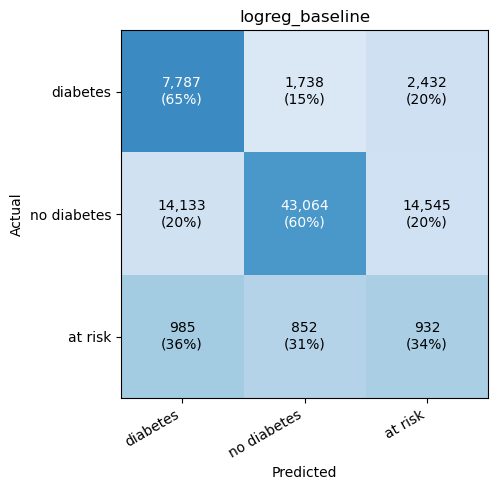

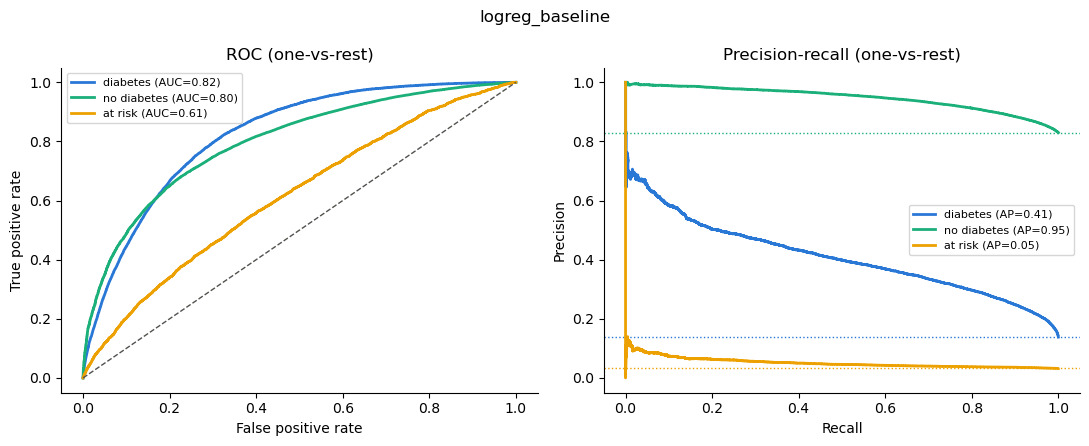

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](3,)","[1.,3.,4.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['bmi','poor_physical_health_days','poor_mental_health_days',..., 'cant_afford_doctor','difficulty_walking','sex']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

In [52]:
baseline_pipeline = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        C=1.0,
        solver="lbfgs",
        random_state=RANDOM_STATE)),
])

config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
          "solver": "lbfgs", "max_iter": 1000, "ordinal_encoding": "onehot"}

log_experiment("logreg_baseline", baseline_pipeline, config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


In [53]:
baseline_results = results_log[-1]

screening_summary = pd.DataFrame({
    "metric": [
        "Diabetes: predicted exactly as diabetes (recall)",
        "Diabetes: flagged as diabetes or at risk",
        "Diabetes: missed (predicted no diabetes)",
        "At risk: predicted exactly as at risk (recall)",
        "At risk: flagged as diabetes or at risk",
        "Screening sensitivity (diabetes + at risk combined)",
        "Screening precision (flagged people who truly need follow-up)",
        "Screening specificity (healthy people not flagged)",
        "Screening F2",
        "Screening F1",
        "People flagged (%)",
    ],
    "value": [
        baseline_results["val_recall/diabetes"],
        baseline_results["screen_sensitivity/diabetes"],
        baseline_results["missed/diabetes"],
        baseline_results["val_recall/at risk"],
        baseline_results["screen_sensitivity/at risk"],
        baseline_results["screen_sensitivity"],
        baseline_results["screen_precision"],
        baseline_results["screen_specificity"],
        baseline_results["screen_f2"],
        baseline_results["screen_f1"],
        baseline_results["pct_flagged"],
    ],
})
screening_summary


,metric,value
0,Diabetes: predicted exactly as diabetes (recall),0.6513
1,Diabetes: flagged as diabetes or at risk,0.8546
2,Diabetes: missed (predicted no diabetes),0.1454
3,At risk: predicted exactly as at risk (recall),0.3366
4,At risk: flagged as diabetes or at risk,0.6923
5,Screening sensitivity (diabetes + at risk comb...,0.8241
6,Screening precision (flagged people who truly ...,0.2973
7,Screening specificity (healthy people not flag...,0.6003
8,Screening F2,0.6085
9,Screening F1,0.4370


## Experiment 2: Apply class imbalance technique then reuse the same baseline logistic regression

[logreg_under_smotenc] SCREENING  sensitivity = 0.597 | precision = 0.361 | F2 = 0.528 | F1 = 0.450 | specificity = 0.783 | flagged = 28.2%
    flagged: diabetes = 0.638 | at risk = 0.420 | diabetics missed = 0.362
    OVERALL  ROC-AUC (OvR) = 0.7248 | macro F1 = 0.4524 | balanced acc = 0.4834 | accuracy = 0.7226
              precision    recall  f1-score   support

    diabetes      0.399     0.487     0.438     11957
 no diabetes      0.904     0.783     0.839     71742
     at risk      0.051     0.181     0.080      2769

    accuracy                          0.723     86468
   macro avg      0.451     0.483     0.452     86468
weighted avg      0.807     0.723     0.759     86468



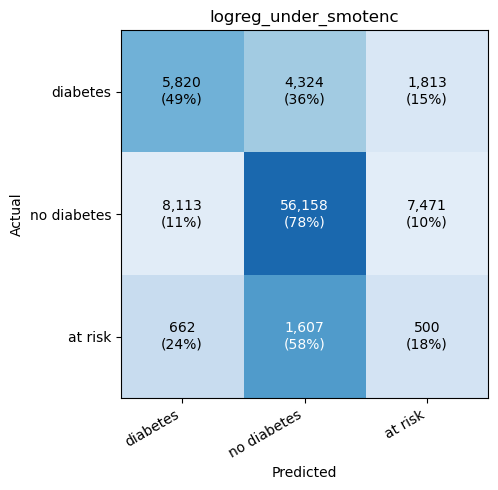

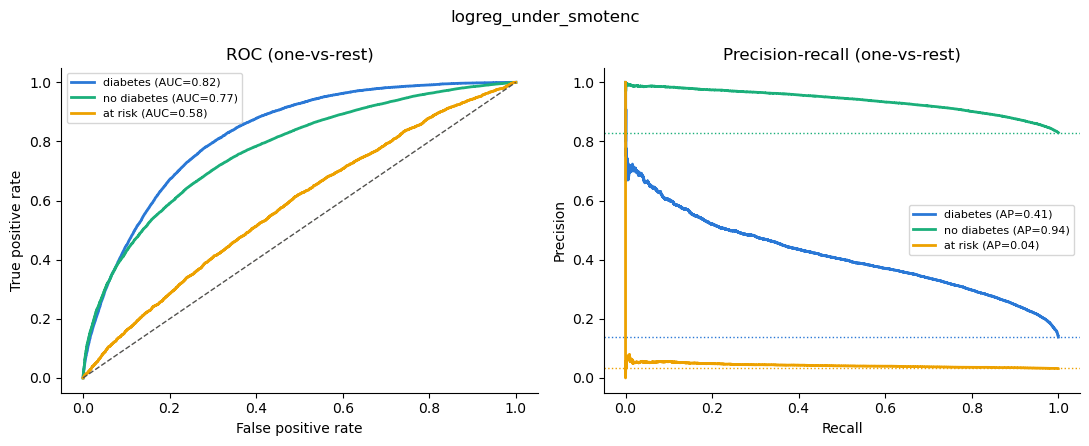

,steps,"[('impute', ...), ('undersample', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[float64](3,)","[1.,3.,4.]"
feature_names_in_,"ndarray[object](28,)","['bmi','poor_physical_health_days','poor_mental_health_days',..., 'cant_afford_doctor','difficulty_walking','sex']"
n_features_in_,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


In [54]:
def undersample_no_diabetes(class_labels):
    """Keep 'no diabetes' (3) at 3x the number of diabetes cases."""
    class_counts = Counter(class_labels)
    return {3: min(class_counts[3], 3 * class_counts[1])}


def oversample_minorities(class_labels):
    """Grow diabetes (1) and at risk (4) to half the size of the (undersampled) majority."""
    class_counts = Counter(class_labels)
    target_count = class_counts[3] // 2
    return {1: max(class_counts[1], target_count), 4: max(class_counts[4], target_count)}


# Step 1: impute only (SMOTENC needs the original categories, before one-hot encoding)
impute_step = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_cols + binary_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# Step 2: scale and one-hot encode, after resampling
encode_step = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", binary_cols),
])

resampled_pipeline = ImbPipeline([
    ("impute", impute_step),
    ("undersample", RandomUnderSampler(sampling_strategy=undersample_no_diabetes,
                                       random_state=RANDOM_STATE)),
    ("oversample", SMOTENC(categorical_features=cat_cols + binary_cols,
                           sampling_strategy=oversample_minorities,
                           random_state=RANDOM_STATE)),
    ("encode", encode_step),
    ("clf", LogisticRegression(max_iter=1000, C=1.0, solver="lbfgs",
                               random_state=RANDOM_STATE)),   # no class_weight: resampling handles the imbalance
])

resampled_config = {"model": "LogisticRegression", "C": 1.0, "class_weight": "none",
                    "resampling": "undersample 3x + SMOTENC to 1/2"}

log_experiment("logreg_under_smotenc", resampled_pipeline, resampled_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

## Experiment 3: Oversampling to the majority class only

[logreg_smotenc_1to1] SCREENING  sensitivity = 0.720 | precision = 0.279 | F2 = 0.547 | F1 = 0.402 | specificity = 0.618 | flagged = 43.9%
    flagged: diabetes = 0.751 | at risk = 0.584 | diabetics missed = 0.249
    OVERALL  ROC-AUC (OvR) = 0.7011 | macro F1 = 0.4158 | balanced acc = 0.4898 | accuracy = 0.6012
              precision    recall  f1-score   support

    diabetes      0.353     0.574     0.437     11957
 no diabetes      0.915     0.618     0.738     71742
     at risk      0.041     0.277     0.072      2769

    accuracy                          0.601     86468
   macro avg      0.437     0.490     0.416     86468
weighted avg      0.809     0.601     0.675     86468



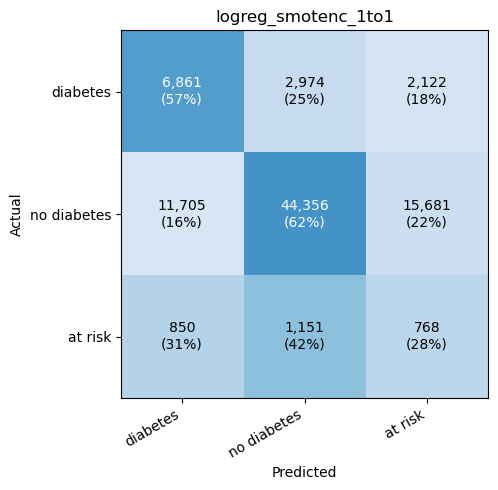

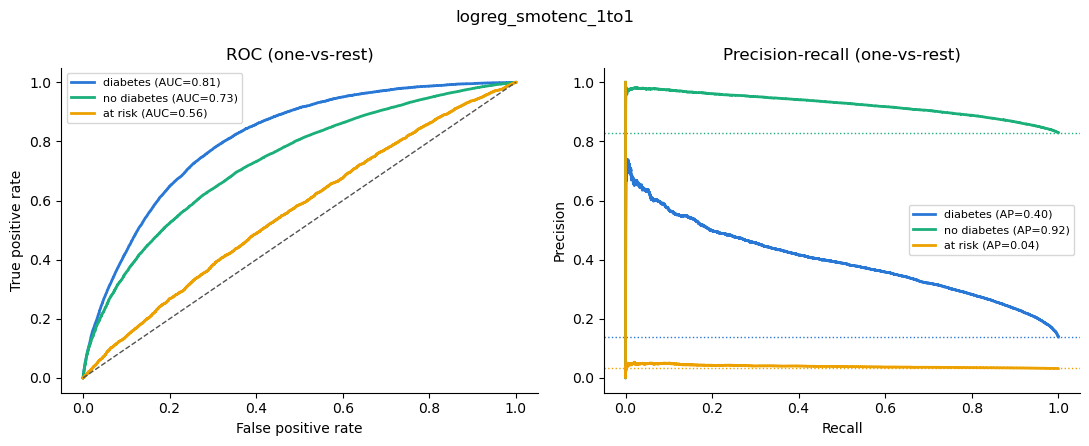

,steps,"[('impute', ...), ('oversample', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[float64](3,)","[1.,3.,4.]"
feature_names_in_,"ndarray[object](28,)","['bmi','poor_physical_health_days','poor_mental_health_days',..., 'cant_afford_doctor','difficulty_walking','sex']"
n_features_in_,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


In [55]:
def oversample_to_majority(class_labels, share_of_majority=1.0):
    """Grow diabetes (1) and at risk (4) to a share of the 'no diabetes' (3) count."""
    class_counts = Counter(class_labels)
    target_count = int(class_counts[3] * share_of_majority)
    return {1: max(class_counts[1], target_count), 4: max(class_counts[4], target_count)}


# Step 1: impute only (SMOTENC needs the original categories, before one-hot encoding)
impute_step = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_cols + binary_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# Step 2: scale and one-hot encode, after resampling
encode_step = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", binary_cols),
])

oversample_pipeline = ImbPipeline([
    ("impute", impute_step),
    ("oversample", SMOTENC(categorical_features=cat_cols + binary_cols,
                           sampling_strategy=oversample_to_majority,
                           random_state=RANDOM_STATE)),
    ("encode", encode_step),
    ("clf", LogisticRegression(max_iter=1000, C=1.0, solver="lbfgs",
                               random_state=RANDOM_STATE)),   # no class_weight: resampling handles it
])

oversample_config = {"model": "LogisticRegression", "C": 1.0, "class_weight": "none",
                     "resampling": "SMOTENC to 1:1:1, no undersampling"}

log_experiment("logreg_smotenc_1to1", oversample_pipeline, oversample_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

## Training with Ensemble Model: Random Forest

Exception ignored in: <function ResourceTracker.__del__ at 0x7281a2f94040>
Traceback (most recent call last):
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x743e323a0040>
Traceback (most recent call last):
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


[rf_depth6_leaf50_estimators_500] SCREENING  sensitivity = 0.819 | precision = 0.301 | F2 = 0.609 | F1 = 0.440 | specificity = 0.609 | flagged = 46.4%
    flagged: diabetes = 0.852 | at risk = 0.679 | diabetics missed = 0.148
    OVERALL  ROC-AUC (OvR) = 0.7459 | macro F1 = 0.4219 | balanced acc = 0.5279 | accuracy = 0.6156
              precision    recall  f1-score   support

    diabetes      0.306     0.746     0.434     11957
 no diabetes      0.943     0.609     0.740     71742
     at risk      0.058     0.229     0.092      2769

    accuracy                          0.616     86468
   macro avg      0.435     0.528     0.422     86468
weighted avg      0.826     0.616     0.677     86468



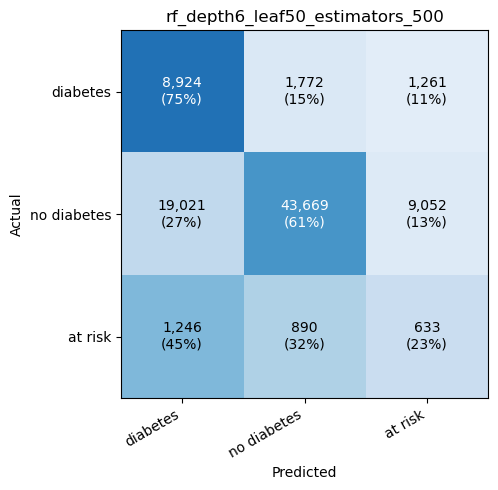

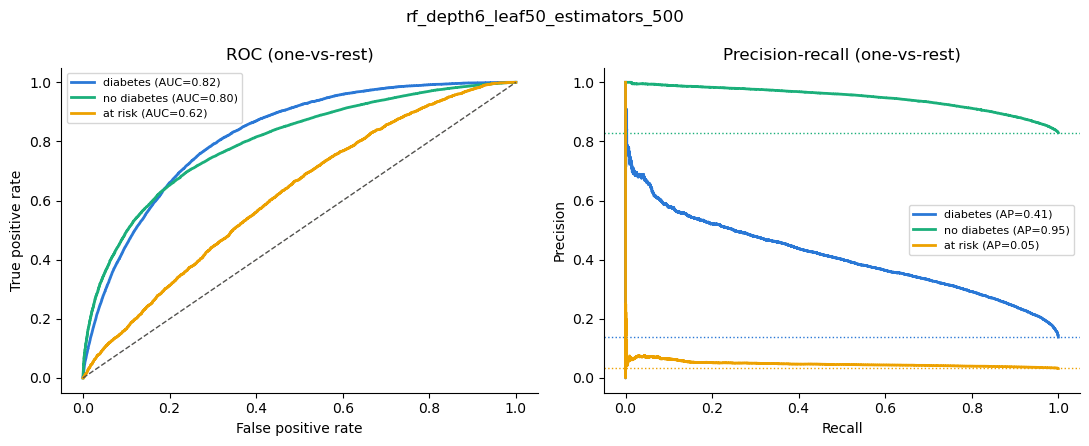

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider

In [56]:
forest_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced_subsample",
    max_depth=6,
    min_samples_leaf=50,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 500,
                 "class_weight": "balanced_subsample", "max_depth": 6,
                 "min_samples_leaf": 50, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth6_leaf50_estimators_500", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


Exception ignored in: <function ResourceTracker.__del__ at 0x71cac5fa8040>
Traceback (most recent call last):
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x7b4f14d8c040>
Traceback (most recent call last):
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception igno

[rf_depth12_leaf100_estimators_1000] SCREENING  sensitivity = 0.809 | precision = 0.310 | F2 = 0.612 | F1 = 0.449 | specificity = 0.631 | flagged = 44.4%
    flagged: diabetes = 0.844 | at risk = 0.659 | diabetics missed = 0.156
    OVERALL  ROC-AUC (OvR) = 0.7533 | macro F1 = 0.4300 | balanced acc = 0.5304 | accuracy = 0.6339
              precision    recall  f1-score   support

    diabetes      0.312     0.748     0.440     11957
 no diabetes      0.942     0.631     0.756     71742
     at risk      0.061     0.212     0.094      2769

    accuracy                          0.634     86468
   macro avg      0.438     0.530     0.430     86468
weighted avg      0.826     0.634     0.691     86468



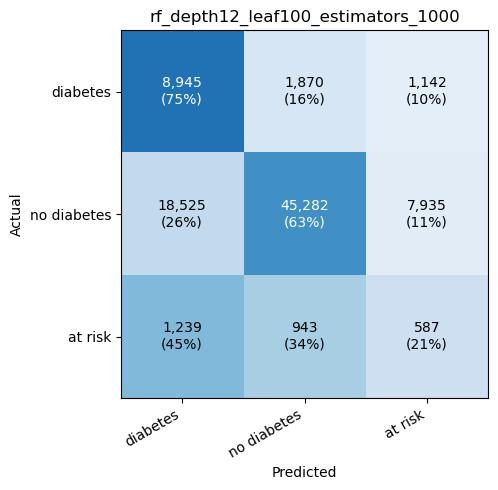

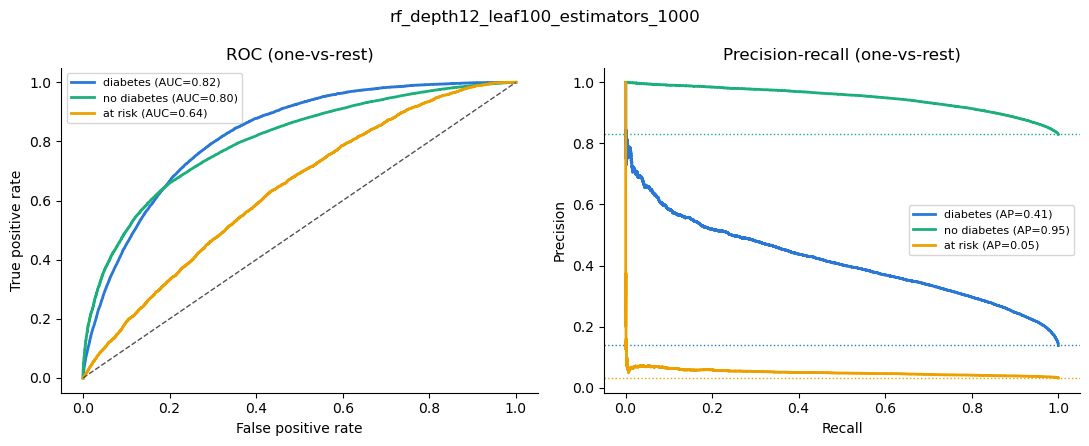

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",100
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consi

In [57]:
forest_model = RandomForestClassifier(
    n_estimators=1000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 1000,
                 "class_weight": "balanced_subsample", "max_depth": 12,
                 "min_samples_leaf": 100, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth12_leaf100_estimators_1000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


[rf_depth12_leaf100_estimators_2000] SCREENING  sensitivity = 0.809 | precision = 0.310 | F2 = 0.612 | F1 = 0.449 | specificity = 0.631 | flagged = 44.4%
    flagged: diabetes = 0.844 | at risk = 0.660 | diabetics missed = 0.156
    OVERALL  ROC-AUC (OvR) = 0.7533 | macro F1 = 0.4302 | balanced acc = 0.5309 | accuracy = 0.6339
              precision    recall  f1-score   support

    diabetes      0.312     0.748     0.440     11957
 no diabetes      0.942     0.631     0.756     71742
     at risk      0.061     0.214     0.095      2769

    accuracy                          0.634     86468
   macro avg      0.438     0.531     0.430     86468
weighted avg      0.826     0.634     0.691     86468



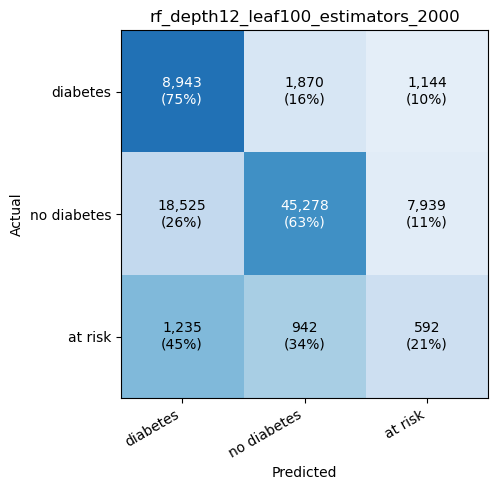

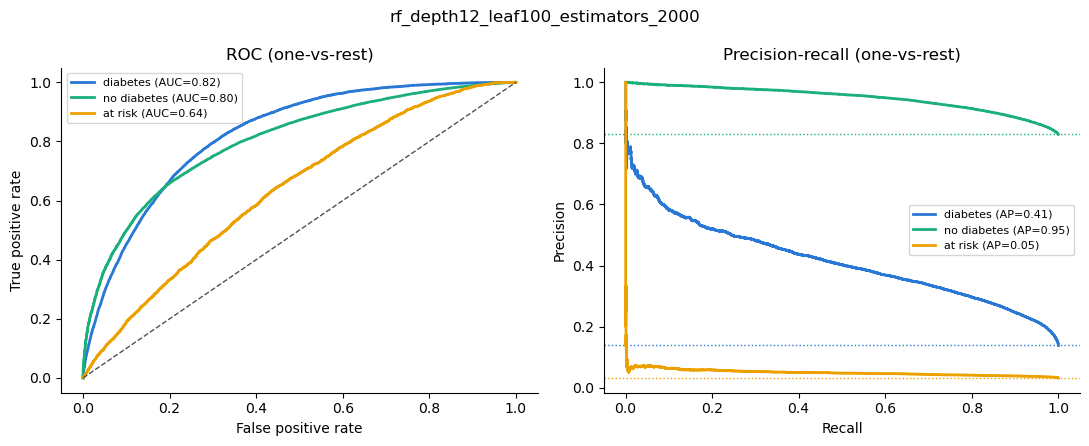

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",2000
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",100
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consi

In [58]:
forest_model = RandomForestClassifier(
    n_estimators=2000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 2000,
                 "class_weight": "balanced_subsample", "max_depth": 12,
                 "min_samples_leaf": 100, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth12_leaf100_estimators_2000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


[rf_depth18_leaf200_estimators_2000] SCREENING  sensitivity = 0.817 | precision = 0.306 | F2 = 0.612 | F1 = 0.445 | specificity = 0.619 | flagged = 45.5%
    flagged: diabetes = 0.850 | at risk = 0.675 | diabetics missed = 0.150
    OVERALL  ROC-AUC (OvR) = 0.7519 | macro F1 = 0.4271 | balanced acc = 0.5314 | accuracy = 0.6236
              precision    recall  f1-score   support

    diabetes      0.312     0.740     0.439     11957
 no diabetes      0.943     0.619     0.747     71742
     at risk      0.059     0.235     0.094      2769

    accuracy                          0.624     86468
   macro avg      0.438     0.531     0.427     86468
weighted avg      0.827     0.624     0.684     86468



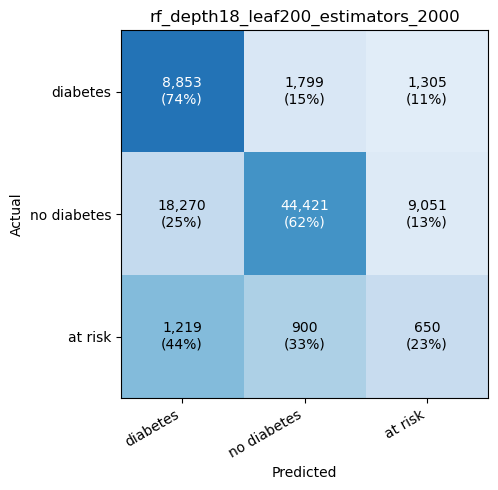

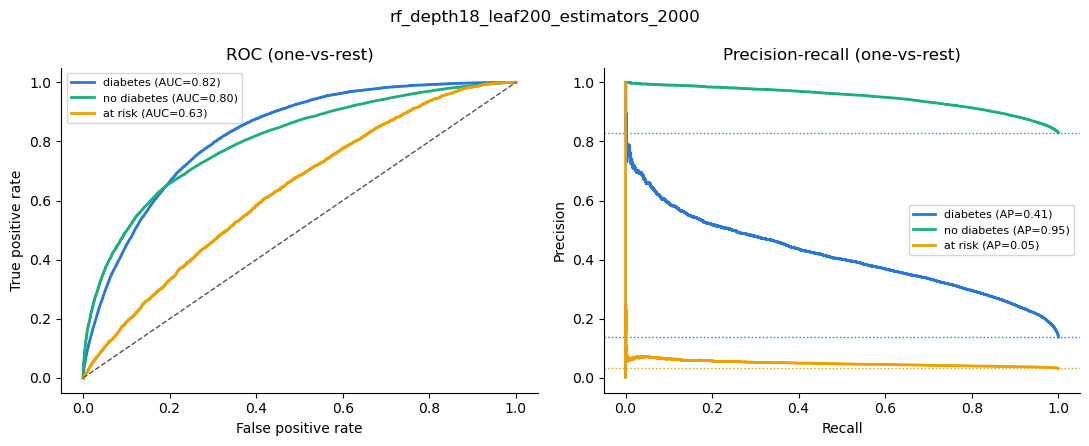

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",2000
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",18
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consi

In [59]:
forest_model = RandomForestClassifier(
    n_estimators=2000,
    class_weight="balanced_subsample",
    max_depth=18,
    min_samples_leaf=200,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 2000,
                 "class_weight": "balanced_subsample", "max_depth": 18,
                 "min_samples_leaf": 200, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth18_leaf200_estimators_2000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


## Notice
Across the random forest variants tested so far, none outperformed the logistic regression baseline on screening F2 (best = 0.61 for both). Since random forests can capture non-linear effects and interactions between features, this suggests that the relationship between the survey answers and diabetes status is largely additive, a pattern a linear model already captures well. It also suggests that several features add little information beyond others (for example, age_group repeats age, and bmi combines height_inches and weight_kg).

To quantify each feature's contribution, we run permutation importance on the baseline logistic regression model: each feature is shuffled in turn, and the resulting drop in screening F2 on the validation set measures how much the model relies on it.


In [60]:
fitted_baseline = baseline_pipeline

importance_result = permutation_importance(
    fitted_baseline, X_val, Y_val,
    scoring=make_scorer(screen_f2),
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "f2_drop_mean": importance_result.importances_mean,
    "f2_drop_std": importance_result.importances_std,
}).sort_values("f2_drop_mean", ascending=False)

feature_importance

,feature,f2_drop_mean,f2_drop_std
5,age,0.039468,0.001080
11,general_health,0.032031,0.002012
17,high_blood_pressure,0.021212,0.001305
18,high_cholesterol,0.017498,0.001155
0,bmi,0.008862,0.000549
4,drink_occasions_per_day,0.008171,0.000631
16,cholesterol_check,0.007771,0.000715
7,weight_kg,0.005989,0.000605
12,age_group,0.005428,0.001138
20,heart_disease,0.002318,0.000334


Attempt training baseline with 13 features


[logreg_13_features] SCREENING  sensitivity = 0.810 | precision = 0.305 | F2 = 0.609 | F1 = 0.443 | specificity = 0.621 | flagged = 45.3%
    flagged: diabetes = 0.846 | at risk = 0.658 | diabetics missed = 0.154
    OVERALL  ROC-AUC (OvR) = 0.7396 | macro F1 = 0.4252 | balanced acc = 0.5224 | accuracy = 0.6147
              precision    recall  f1-score   support

    diabetes      0.330     0.651     0.438     11957
 no diabetes      0.941     0.621     0.748     71742
     at risk      0.053     0.295     0.089      2769

    accuracy                          0.615     86468
   macro avg      0.441     0.522     0.425     86468
weighted avg      0.828     0.615     0.684     86468



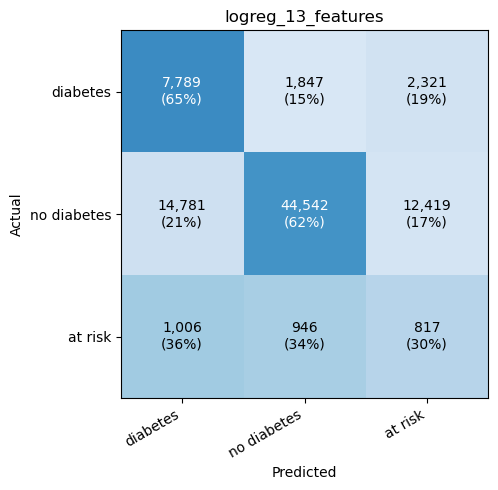

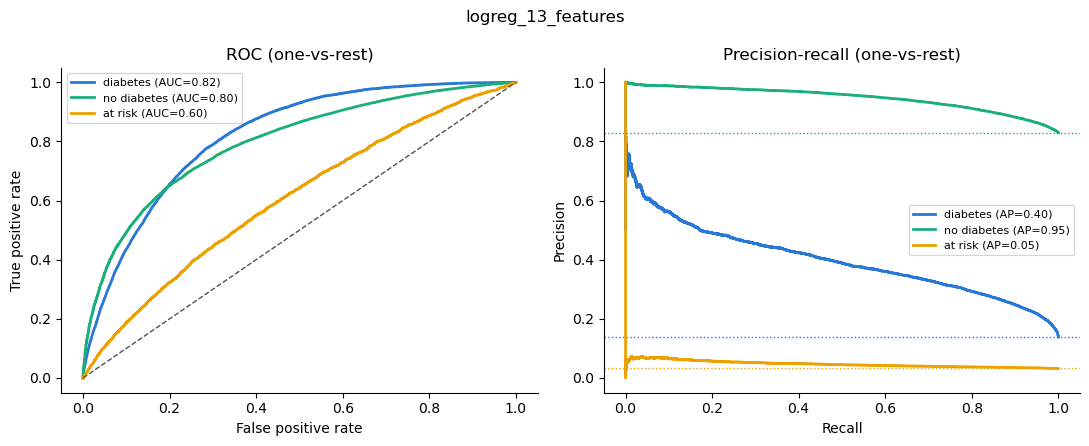

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](3,)","[1.,3.,4.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','bmi','weight_kg',...,'heart_disease','kidney_disease', 'difficulty_walking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passt

In [61]:
selected_features = [
    # numeric
    "age", "bmi", "weight_kg", "drink_occasions_per_day",
    # ordinal / categorical
    "general_health", "cholesterol_check", "high_cholesterol", "education", "income",
    # binary
    "high_blood_pressure", "heart_disease", "kidney_disease", "difficulty_walking",
]

selected_numeric_cols = [column for column in numeric_cols if column in selected_features]
selected_cat_cols = [column for column in cat_cols if column in selected_features]
selected_binary_cols = [column for column in binary_cols if column in selected_features]

selected_preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), selected_numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), selected_cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), selected_binary_cols),
])

selected_pipeline = Pipeline([
    ("prep", selected_preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0,
                               solver="lbfgs", random_state=RANDOM_STATE)),
])

selected_config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
                   "n_features": len(selected_features), "features": "top-13 by permutation F2"}

log_experiment("logreg_13_features", selected_pipeline, selected_config,
               X_train[selected_features], Y_train, X_val[selected_features], Y_val, do_cv=False)


[lgbm_baseline] SCREENING  sensitivity = 0.796 | precision = 0.319 | F2 = 0.612 | F1 = 0.455 | specificity = 0.651 | flagged = 42.5%
    flagged: diabetes = 0.831 | at risk = 0.645 | diabetics missed = 0.169
    OVERALL  ROC-AUC (OvR) = 0.7516 | macro F1 = 0.4354 | balanced acc = 0.5274 | accuracy = 0.6460
              precision    recall  f1-score   support

    diabetes      0.325     0.718     0.447     11957
 no diabetes      0.940     0.651     0.769     71742
     at risk      0.057     0.213     0.090      2769

    accuracy                          0.646     86468
   macro avg      0.440     0.527     0.435     86468
weighted avg      0.826     0.646     0.703     86468



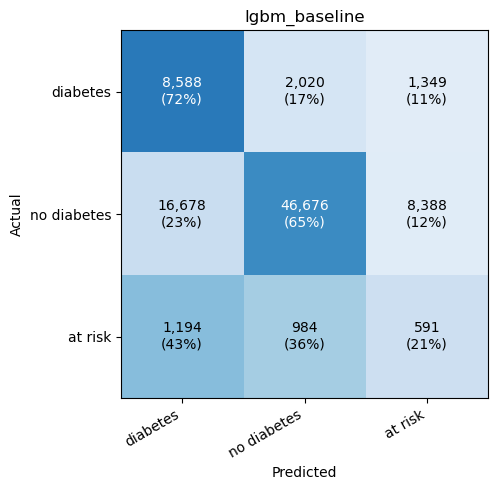

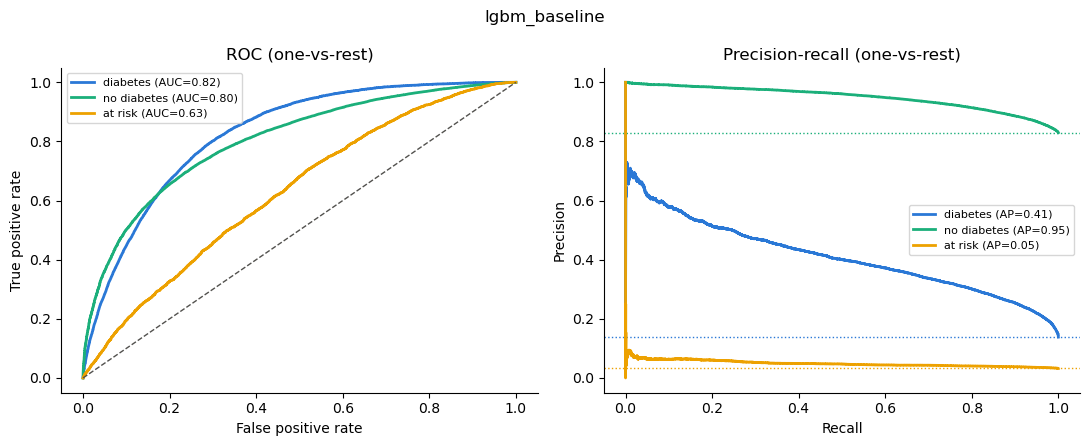

,learning_rate,0.05
,n_estimators,1000
,class_weight,'balanced'
,min_child_samples,50
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,42
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'


In [62]:
lightgbm_model = LGBMClassifier(
    class_weight="balanced",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)

lightgbm_config = {"model": "LightGBM", "class_weight": "balanced", "n_estimators": 1000,
                   "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 50,
                   "subsample": 0.8, "colsample_bytree": 0.8, "categorical": "ordinal as numbers"}

log_experiment("lgbm_baseline", lightgbm_model, lightgbm_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

In [ ]:
fitted_lightgbm = lightgbm_model

lightgbm_importance_result = permutation_importance(
    fitted_lightgbm, X_val, Y_val,
    scoring=make_scorer(screen_f2),
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

lightgbm_feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "f2_drop_mean": lightgbm_importance_result.importances_mean,
    "f2_drop_std": lightgbm_importance_result.importances_std,
}).sort_values("f2_drop_mean", ascending=False)

lightgbm_feature_importance


In [ ]:
comparison_columns = [
    "run_name",
    "screen_f2", "screen_f1", "screen_sensitivity", "screen_precision", "screen_specificity",
    "screen_sensitivity/diabetes", "screen_sensitivity/at risk", "missed/diabetes", "pct_flagged",
    "val_recall/diabetes", "val_recall/at risk", "val_precision/diabetes", "val_precision/at risk",
    "val_pr_auc/diabetes", "val_pr_auc/at risk", "val_roc_auc_ovr", "val_f1_macro",
]
results_table = pd.DataFrame(results_log)
results_table[[column for column in comparison_columns if column in results_table.columns]] \
    .sort_values("screen_f2", ascending=False)


,run_name,screen_f2,screen_f1,screen_sensitivity,screen_precision,screen_specificity,screen_sensitivity/diabetes,screen_sensitivity/at risk,missed/diabetes,pct_flagged,val_recall/diabetes,val_recall/at risk,val_precision/diabetes,val_precision/at risk,val_pr_auc/diabetes,val_pr_auc/at risk,val_roc_auc_ovr,val_f1_macro
7,rf_depth18_leaf100_estimators_2000,0.6141,0.4535,0.8039,0.3159,0.6426,0.8405,0.6457,0.1595,43.3444,0.7499,0.1979,0.3121,0.0626,0.4138,0.0509,0.7538,0.4332
6,rf_depth12_leaf100_estimators_2000,0.6123,0.4487,0.8090,0.3104,0.6311,0.8436,0.6598,0.1564,44.3840,0.7479,0.2138,0.3116,0.0612,0.4143,0.0501,0.7533,0.4302
5,rf_depth12_leaf100_estimators_1000,0.6123,0.4487,0.8090,0.3105,0.6312,0.8436,0.6594,0.1564,44.3783,0.7481,0.2120,0.3116,0.0607,0.4141,0.0501,0.7533,0.4300
8,rf_depth18_leaf200_estimators_2000,0.6120,0.4448,0.8167,0.3057,0.6192,0.8495,0.6750,0.1505,45.5059,0.7404,0.2347,0.3124,0.0591,0.4135,0.0495,0.7519,0.4271
4,rf_depth6_leaf50_estimators_500,0.6090,0.4398,0.8192,0.3006,0.6087,0.8518,0.6786,0.1482,46.4183,0.7463,0.2286,0.3057,0.0578,0.4106,0.0475,0.7459,0.4219
3,rf_depth6_leaf50,0.6088,0.4395,0.8192,0.3003,0.6083,0.8521,0.6768,0.1479,46.4519,0.7471,0.2257,0.3053,0.0573,0.4105,0.0475,0.7457,0.4214
0,logreg_baseline,0.6085,0.4370,0.8241,0.2973,0.6003,0.8546,0.6923,0.1454,47.2013,0.6513,0.3366,0.3400,0.0520,0.4082,0.0515,0.7447,0.4235
2,logreg_smotenc_1to1,0.5471,0.4022,0.7199,0.2791,0.6183,0.7513,0.5843,0.2487,43.9319,0.5738,0.2774,0.3534,0.0414,0.3956,0.0393,0.7011,0.4158
1,logreg_under_smotenc,0.5280,0.4498,0.5972,0.3608,0.7828,0.6384,0.4196,0.3616,28.1942,0.4867,0.1806,0.3988,0.0511,0.4139,0.0423,0.7248,0.4524


## View the experiments in TensorBoard
Every run above is logged to `LOG_DIR`. The cell below opens the TensorBoard dashboard inside the notebook.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir {LOG_DIR}

Exception ignored in: <function ResourceTracker.__del__ at 0x75ad2c59c040>
Traceback (most recent call last):
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x71e5de39c040>
Traceback (most recent call last):
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/bode-murairi/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception igno

Citations:
1. Vounzoulaki E, Khunti K, Abner SC, Tan BK, Davies MJ, Gillies CL. Progression to type 2 diabetes in women with a known history of gestational diabetes: systematic review and meta-analysis. BMJ. 2020;369:m1361.
https://www.bmj.com/content/bmj/369/bmj.m1361.full.pdf